# Laser Particles as a Physical Reservoir

Goal: test, in simulation, whether one laser particle can work as a reservoir in reservoir computing. The laser is compared with a standard software reservoir, the Echo State Network (ESN). Both are tested on the NARMA10 task.

Sections:
0. Task and score (NARMA10, NMSE)
1. ESN baseline
2. The laser by itself (rate equations)
3. The laser as a reservoir (without and with a delay loop)
4. Exploration: photon lifetime τ_c
5. The laser's own noise

In [1]:
import os
# One thread per numpy call: the matrices here are small, and extra threads slow things down a lot
for var in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[var] = "1"

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 0. Task and score

**NARMA10.** The input u(k) is a random number between 0 and 0.5. The target y(k) follows this rule:

y(k+1) = 0.3·y(k) + 0.05·y(k)·[y(k) + ... + y(k−9)] + 1.5·u(k−9)·u(k) + 0.1

To predict y(k+1), a model needs two things:
- **memory**: the rule uses u(k−9), the input from 9 steps earlier.
- **nonlinearity**: the rule multiplies terms, for example u(k−9)·u(k).

**NMSE** (normalized mean squared error) = mean((prediction − target)²) / var(target). 0 is perfect. 1 is the error of always predicting the average of the target. Appeltant et al. report NRMSE, which is √NMSE.

In [2]:
def narma10(n_steps, seed):
    """Return input u and NARMA10 output y, each of length n_steps."""
    rng = np.random.default_rng(seed)
    u = rng.uniform(0, 0.5, n_steps)
    y = np.zeros(n_steps)
    for k in range(9, n_steps - 1):
        y[k + 1] = (0.3 * y[k]
                    + 0.05 * y[k] * np.sum(y[k - 9:k + 1])
                    + 1.5 * u[k - 9] * u[k]
                    + 0.1)
    # NARMA10 can blow up for unlucky inputs; stop here if it does
    assert np.all(np.isfinite(y)) and y.max() < 10, "NARMA10 diverged, try another seed"
    return u, y


def nmse(prediction, target):
    return np.mean((prediction - target) ** 2) / np.var(target)

**Alignment.** y(k+1) depends only on inputs up to u(k). So after the model sees u(k), it must predict y(k+1). The code stores this as a target sequence `d`, with d(k) = y(k+1).

**Split.** The first 200 steps are not used. This is called the washout. In these steps the reservoir still depends on its starting state, and y has not yet reached its normal range. The other steps are split into three parts:
- train: used to fit the readout weights.
- validation: used to choose settings.
- test: used once, for the final score.

The laser reservoir uses the same seed and the same split. So both models get exactly the same data.

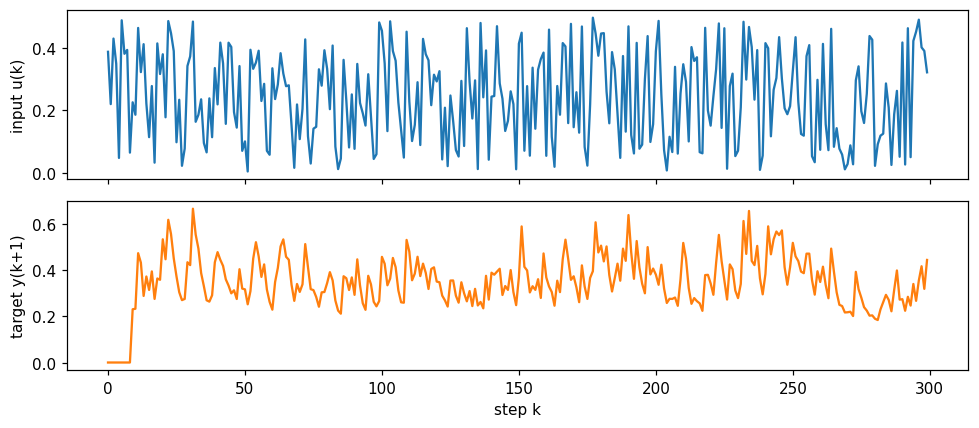

In [3]:
DATA_SEED = 42
WASHOUT, N_TRAIN, N_VAL, N_TEST = 200, 3000, 800, 1000
n_steps = WASHOUT + N_TRAIN + N_VAL + N_TEST

u_all, y_all = narma10(n_steps + 1, DATA_SEED)
u = u_all[:-1]   # input fed at step k
d = y_all[1:]    # target at step k is y(k+1)

train = slice(WASHOUT, WASHOUT + N_TRAIN)
val = slice(WASHOUT + N_TRAIN, WASHOUT + N_TRAIN + N_VAL)
test = slice(WASHOUT + N_TRAIN + N_VAL, n_steps)

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(u[:300]); ax[0].set_ylabel("input u(k)")
ax[1].plot(d[:300], color="C1"); ax[1].set_ylabel("target y(k+1)")
ax[1].set_xlabel("step k")
plt.tight_layout(); plt.show()

## 1. Echo State Network (ESN) baseline

An ESN is a recurrent network. Its internal weights are random and fixed. Only the output weights are trained.

State update, for N nodes:

x(k) = tanh( W·x(k−1) + W_in·u(k) + b )

- **W** (N×N): random weights between nodes. About 10% of them are nonzero.
- **Spectral radius ρ**: the largest absolute eigenvalue of W. W is rescaled so that this value is ρ, with ρ < 1. Then the effect of an old input becomes smaller at every step, so the state depends mostly on recent inputs. This is called fading memory.
- **W_in** (N values): random input weights, between −s and s. The input scaling s sets how far the nodes move into the curved part of tanh. A larger s gives a more nonlinear response.
- **b** (N values): a random constant for each node. It places each node at a different point on the tanh curve.

**Readout.** The prediction is a weighted sum: ŷ(k) = W_out · [x(k), u(k), 1]. W_out is found by ridge regression. Ridge regression is least squares with an extra penalty α·|W_out|². The penalty keeps the weights small:

W_out = (FᵀF + αI)⁻¹ Fᵀd, where each row of F is [x(k), u(k), 1].

In [4]:
def make_esn(n_nodes, spectral_radius, input_scale, seed, density=0.1, bias_scale=0.1):
    rng = np.random.default_rng(seed)
    W = rng.uniform(-1, 1, (n_nodes, n_nodes))
    W *= rng.random((n_nodes, n_nodes)) < density   # keep ~10% of connections
    W *= spectral_radius / np.max(np.abs(np.linalg.eigvals(W)))
    W_in = rng.uniform(-input_scale, input_scale, n_nodes)
    b = rng.uniform(-bias_scale, bias_scale, n_nodes)
    return W, W_in, b


def run_esn(W, W_in, b, u):
    """Drive the ESN with input u. Return the state matrix, one row per step."""
    x = np.zeros(W.shape[0])
    states = np.zeros((len(u), W.shape[0]))
    for k in range(len(u)):
        x = np.tanh(W @ x + W_in * u[k] + b)
        states[k] = x
    return states


def features(states, u):
    """Readout features: reservoir state, raw input, and a constant 1."""
    return np.column_stack([states, u, np.ones(len(u))])


def train_readout(F, target, ridge):
    return np.linalg.solve(F.T @ F + ridge * np.eye(F.shape[1]), F.T @ target)

### 1.1 Choose ρ, s and α on the validation set

A small grid of values is tried. Each setting gets the average validation NMSE over 3 random reservoirs. One random reservoir alone can score unusually well or unusually badly.

In [5]:
N_NODES = 100   # same as the "traditional RC" in Appeltant et al.

results = []
for rho in [0.8, 0.9, 0.95]:
    for s in [0.05, 0.1, 0.2]:
        # Ridge does not change the states, so run each reservoir once per (rho, s)
        Fs = [features(run_esn(*make_esn(N_NODES, rho, s, seed), u), u) for seed in range(3)]
        for ridge in [1e-8, 1e-6, 1e-4]:
            scores = [nmse(F[val] @ train_readout(F[train], d[train], ridge), d[val]) for F in Fs]
            results.append((np.mean(scores), rho, s, ridge))

results.sort()
print("Best 5 settings (validation NMSE, rho, s, ridge):")
for r in results[:5]:
    print(f"  {r[0]:.4f}   rho={r[1]}  s={r[2]}  ridge={r[3]:g}")
_, RHO, S_IN, RIDGE = results[0]

Best 5 settings (validation NMSE, rho, s, ridge):
  0.1106   rho=0.9  s=0.1  ridge=1e-08
  0.1176   rho=0.95  s=0.1  ridge=1e-08
  0.1178   rho=0.8  s=0.1  ridge=1e-08
  0.1184   rho=0.9  s=0.05  ridge=1e-08
  0.1186   rho=0.9  s=0.2  ridge=1e-08


### 1.2 Final score on the test set

The chosen settings are fixed. The readout is trained on train and validation together. The score is measured on the test set. This is repeated for 10 random reservoirs. The result is the mean ± standard deviation.

In [6]:
train_val = slice(WASHOUT, WASHOUT + N_TRAIN + N_VAL)

test_scores = []
for seed in range(10):
    F = features(run_esn(*make_esn(N_NODES, RHO, S_IN, seed), u), u)
    W_out = train_readout(F[train_val], d[train_val], RIDGE)
    test_scores.append(nmse(F[test] @ W_out, d[test]))
    if seed == 0:
        esn_prediction = F[test] @ W_out

esn_nmse, esn_std = np.mean(test_scores), np.std(test_scores)
print(f"ESN test NMSE  = {esn_nmse:.4f} ± {esn_std:.4f}  (10 reservoirs)")
print(f"ESN test NRMSE = {np.sqrt(esn_nmse):.3f}")
print("Reference (Appeltant et al., as NMSE): shift register 0.16, traditional RC 0.032, delay reservoir 0.0225")

ESN test NMSE  = 0.0667 ± 0.0135  (10 reservoirs)
ESN test NRMSE = 0.258
Reference (Appeltant et al., as NMSE): shift register 0.16, traditional RC 0.032, delay reservoir 0.0225


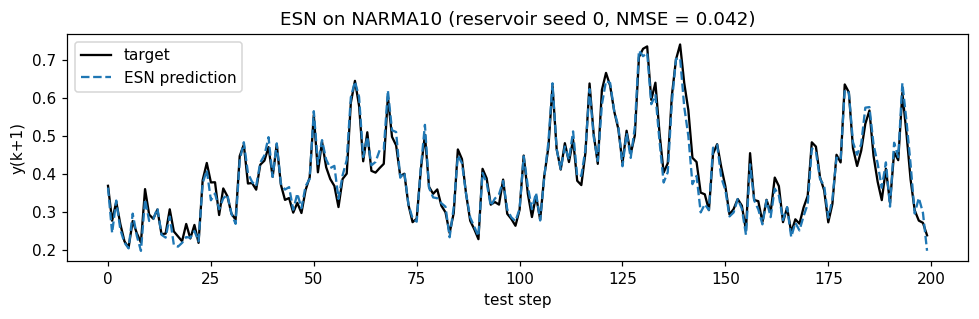

In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(d[test][:200], label="target", color="k")
ax.plot(esn_prediction[:200], label="ESN prediction", color="C0", ls="--")
ax.set_xlabel("test step"); ax.set_ylabel("y(k+1)")
ax.set_title(f"ESN on NARMA10 (reservoir seed 0, NMSE = {test_scores[0]:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the result.** Appeltant et al. report that a memory-only model (a shift register) scores NMSE ≈ 0.16. The ESN scores below that, so its nonlinearity helps. (Section 3.2 builds a memory-only reference on this data. It scores 0.326.)

The ESN does not reach Appeltant's value for traditional reservoir computing (NMSE ≈ 0.032). Their paper does not give the full reservoir design or the training length. So this notebook uses its own ESN score as the baseline. The laser reservoir is compared with it, on the same data and split.

## 2. The laser by itself

This section does not use NARMA10 or a readout. It only checks how the laser responds to its pump. The model is the rate equations from Cho et al. (PRL 2016, Eqs. 1–2):

dN₁/dt = P(t) − β·N₁·q/τ − N₁/τ

dq/dt = β·N₁·q/τ + β·N₁/τ − q/τ_c

- **N₁**: number of excited carriers. These are electrons excited by the pump.
- **q**: number of photons in the laser mode.
- **P(t)**: pump rate: the number of carriers excited per unit time. In Section 3, the input is added here.
- **τ**: carrier lifetime. **τ_c**: photon lifetime. **β**: the fraction of spontaneous emission that goes into the laser mode.

**What each term means.** The pump adds carriers. Carriers are lost by stimulated emission (β·N₁·q/τ) and by spontaneous emission (N₁/τ). Photons are added by stimulated emission and by a small part β of spontaneous emission. Photons are lost when they leave the laser (q/τ_c).

**Units.** Time is measured in units of τ, so τ = 1. The paper gives τ ≈ 2 ns, so one time unit is 2 ns.

**Normalized quantities used in the plots:**
- pump p = P / P_th. P_th = 1/(β·τ_c) is the threshold pump. Lasing starts at p = 1.
- carriers n = N₁ / N_th, where N_th = τ/(β·τ_c).
- output L = β·q. This equals the emitted power q/τ_c divided by P_th. It is the quantity in the paper's Eq. 3.

In [8]:
TAU = 1.0       # carrier lifetime; sets the time unit
TAU_C = 0.01    # photon lifetime, in units of TAU
BETA = 1e-3     # spontaneous emission factor (paper's fit: 1.3e-3)

P_TH = 1 / (BETA * TAU_C)    # threshold pump rate
N_TH = TAU / (BETA * TAU_C)  # carrier number at threshold
DT = 1e-3                    # integration time step (= TAU_C / 10)


def rate_equations(N, q, P, beta, tau_c):
    dN = P - beta * N * q / TAU - N / TAU
    dq = beta * N * q / TAU + beta * N / TAU - q / tau_c
    return dN, dq


def simulate_laser(P, dt=DT, beta=BETA, tau_c=TAU_C, N0=0.0, q0=0.0):
    """Solve the rate equations with 4th-order Runge-Kutta.

    P holds the pump rate for each time step (constant within a step).
    Returns N and q at the start of each step, so they line up with P.
    """
    N = np.empty(len(P))
    q = np.empty(len(P))
    n, s = N0, q0
    for i in range(len(P)):
        N[i], q[i] = n, s
        k1 = rate_equations(n, s, P[i], beta, tau_c)
        k2 = rate_equations(n + dt / 2 * k1[0], s + dt / 2 * k1[1], P[i], beta, tau_c)
        k3 = rate_equations(n + dt / 2 * k2[0], s + dt / 2 * k2[1], P[i], beta, tau_c)
        k4 = rate_equations(n + dt * k3[0], s + dt * k3[1], P[i], beta, tau_c)
        n += dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        s += dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return N, q


def steady_output(p, beta=BETA):
    """Paper's Eq. 3: output L = beta*q when the pump is held at p for a long time."""
    return (p - 1 + np.sqrt((p - 1) ** 2 + 4 * beta * p)) / 2

### 2.1 Threshold: slow pump ramp

The pump rises slowly from p = 0 to p = 3 over 300 time units. This is slow compared with τ. So at every moment the laser is close to its steady state. The simulated output should then match Eq. 3. This checks the code.

The middle panel also shows Eq. 3 for two other β values. A smaller β gives a sharper bend at threshold. That means a stronger nonlinearity.

p = 0.5: simulated L = 0.0010, Eq. 3 gives 0.0010
p = 1.5: simulated L = 0.5026, Eq. 3 gives 0.5030
p = 2.5: simulated L = 1.5015, Eq. 3 gives 1.5017


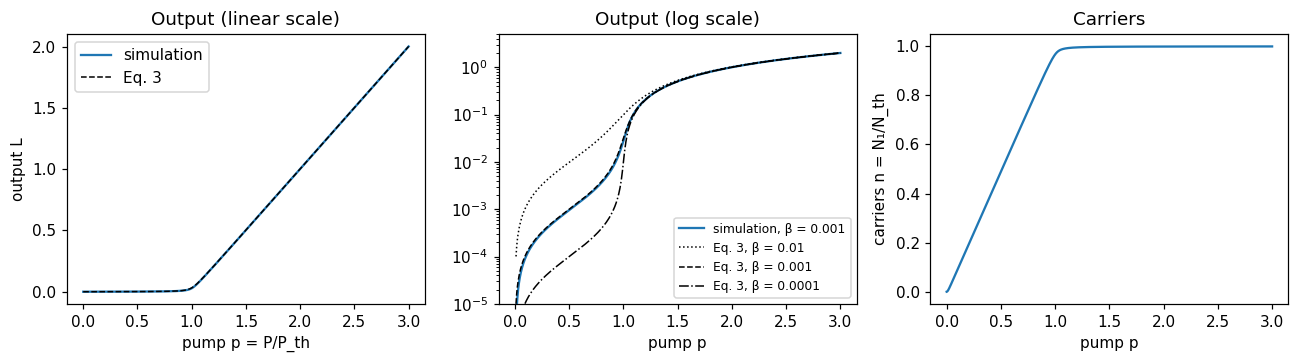

In [9]:
t_ramp = np.arange(0, 300, DT)
p_ramp = t_ramp / 100
N, q = simulate_laser(p_ramp * P_TH)
L_ramp = BETA * q

for p_check in [0.5, 1.5, 2.5]:
    i = np.argmin(np.abs(p_ramp - p_check))
    print(f"p = {p_check}: simulated L = {L_ramp[i]:.4f}, Eq. 3 gives {steady_output(p_check):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(p_ramp, L_ramp, label="simulation")
ax[0].plot(p_ramp, steady_output(p_ramp), "k--", lw=1, label="Eq. 3")
ax[0].set_xlabel("pump p = P/P_th"); ax[0].set_ylabel("output L"); ax[0].set_title("Output (linear scale)")
ax[0].legend()

p_grid = np.linspace(0.01, 3, 500)
ax[1].semilogy(p_ramp, L_ramp, label=f"simulation, β = {BETA:g}")
for b, style in [(1e-2, ":"), (BETA, "--"), (1e-4, "-.")]:
    ax[1].semilogy(p_grid, steady_output(p_grid, b), "k" + style, lw=1, label=f"Eq. 3, β = {b:g}")
ax[1].set_ylim(1e-5, 5); ax[1].set_xlabel("pump p"); ax[1].set_title("Output (log scale)")
ax[1].legend(fontsize=8)

ax[2].plot(p_ramp, N / N_TH)
ax[2].set_xlabel("pump p"); ax[2].set_ylabel("carriers n = N₁/N_th"); ax[2].set_title("Carriers")
plt.tight_layout(); plt.show()

**What the plots show.**
- Below p = 1 the output is very small. Above p = 1 it rises in a straight line, L ≈ p − 1. The bend at p = 1 is the threshold nonlinearity.
- The carriers rise with the pump until p = 1. Above that, they stay at n ≈ 1, because every extra carrier is turned into photons by stimulated emission. This is called gain clamping.
- Just below threshold, the simulation is slightly below Eq. 3. The ramp is not infinitely slow, so the output is a little behind the pump.

### 2.2 Speed of response: pump steps

Two step tests:
- **Turn-on.** The pump jumps from 0 to p = 2 at t = 1. Light appears only after the carriers reach threshold. With no photons, N₁ grows as Pτ(1 − e^(−t/τ)). So it reaches N_th after τ·ln(p/(p−1)) = ln 2 ≈ 0.69 time units.
- **Small step above threshold.** The laser starts at steady state at p = 1.2. Then the pump jumps to p = 1.5. This is closer to how the laser runs as a reservoir. The output goes above its final value, then oscillates up and down before it settles. These are called relaxation oscillations. Energy moves back and forth between the carriers and the photons. The expected period is about 2π / √((p − 1)/(τ·τ_c)).

Turn-on: carriers reach threshold 0.695 after the step (expected ln 2 = 0.693)
         output reaches half its final value 0.957 after the step
Small step: oscillation period = 0.890 (expected 0.889)


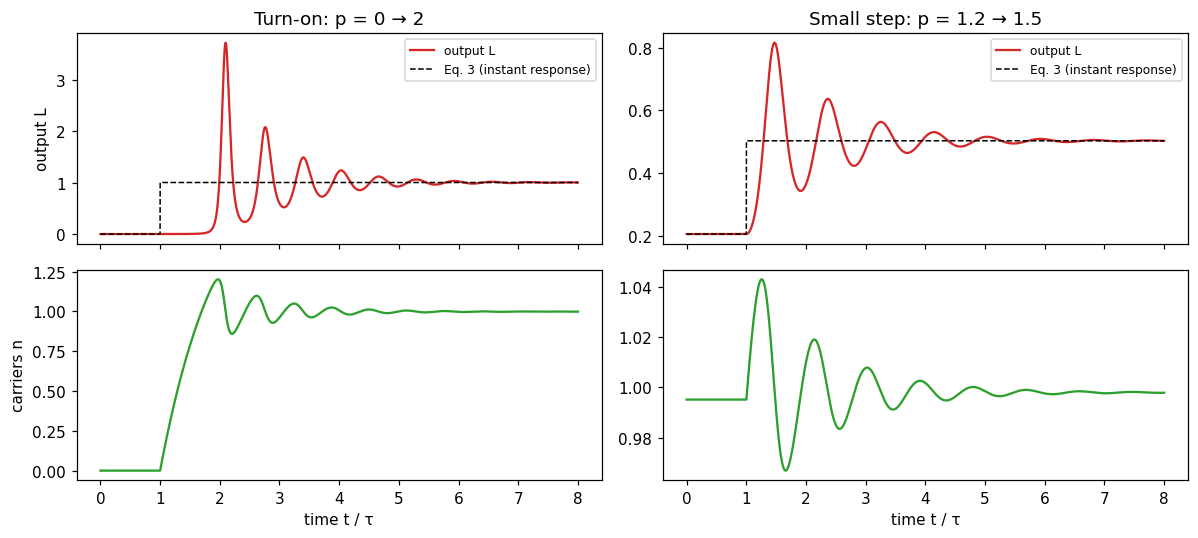

In [10]:
from scipy.signal import find_peaks

t_step = np.arange(0, 8, DT)

# Turn-on from zero
p_on = np.where(t_step < 1, 0.0, 2.0)
N_on, q_on = simulate_laser(p_on * P_TH)
t_threshold = t_step[np.argmax(N_on >= N_TH)]
print(f"Turn-on: carriers reach threshold {t_threshold - 1:.3f} after the step (expected ln 2 = {np.log(2):.3f})")
print(f"         output reaches half its final value {t_step[np.argmax(BETA * q_on > 0.5)] - 1:.3f} after the step")

# Small step, starting from the steady state at p = 1.2
p_small = np.where(t_step < 1, 1.2, 1.5)
L0 = steady_output(1.2)
N_small, q_small = simulate_laser(p_small * P_TH, N0=N_TH * (1.2 / (1 + L0)), q0=L0 / BETA)
after = t_step >= 1
peaks, _ = find_peaks(q_small[after])
print(f"Small step: oscillation period = {np.mean(np.diff(t_step[after][peaks][:4])):.3f} "
      f"(expected {2 * np.pi / np.sqrt(0.5 / (TAU * TAU_C)):.3f})")

fig, ax = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for col, (p, N, q, title) in enumerate([(p_on, N_on, q_on, "Turn-on: p = 0 → 2"),
                                        (p_small, N_small, q_small, "Small step: p = 1.2 → 1.5")]):
    ax[0, col].plot(t_step, BETA * q, color="C3", label="output L")
    ax[0, col].plot(t_step, steady_output(p), "k--", lw=1, label="Eq. 3 (instant response)")
    ax[0, col].set_title(title); ax[0, col].legend(fontsize=8)
    ax[1, col].plot(t_step, N / N_TH, color="C2")
    ax[1, col].set_xlabel("time t / τ")
ax[0, 0].set_ylabel("output L"); ax[1, 0].set_ylabel("carriers n")
plt.tight_layout(); plt.show()

### 2.3 Following a changing pump: sine waves

The pump is p(t) = p_mean + 0.3·sin(2π·f·t). The dashed line is Eq. 3 applied at every moment. It is the output the laser would give if it responded with no delay. The difference between the two lines shows two separate effects:

- **Nonlinearity**: the shape of Eq. 3. It matters when the pump crosses threshold.
- **Memory**: the gap between the real output and the no-delay output. It appears when the pump changes faster than the laser can respond. Then the output depends on earlier pump values.

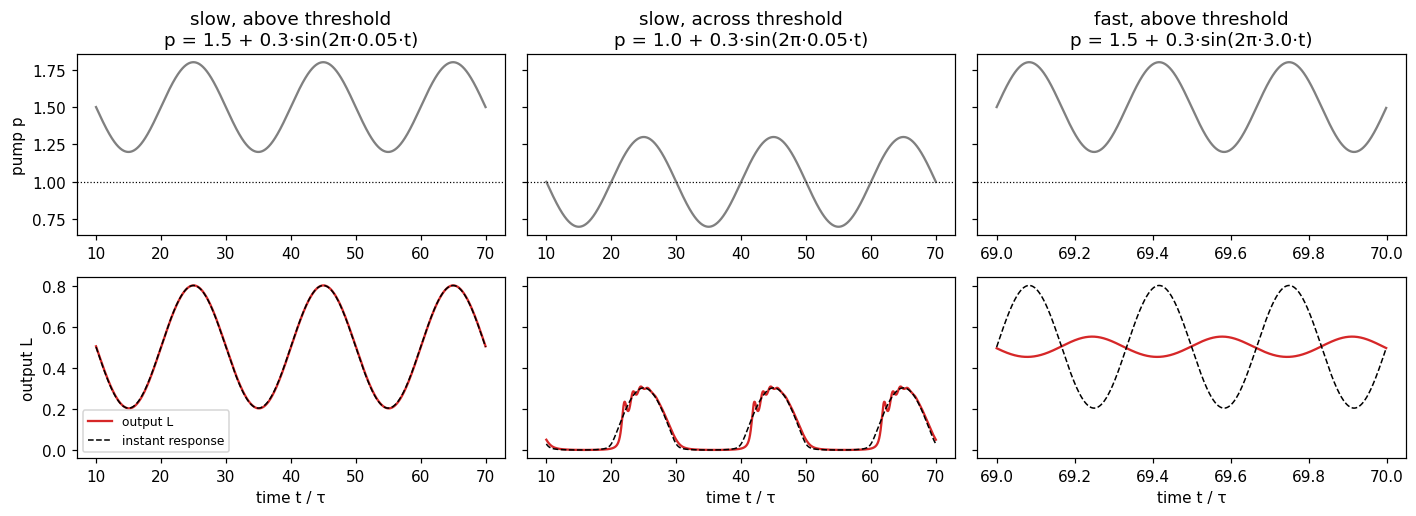

In [11]:
t_sin = np.arange(0, 70, DT)
cases = [(1.5, 0.05, "slow, above threshold"),
         (1.0, 0.05, "slow, across threshold"),
         (1.5, 3.0, "fast, above threshold")]

fig, ax = plt.subplots(2, 3, figsize=(13, 4.8), sharey="row")
for col, (p_mean, f, title) in enumerate(cases):
    p_sin = p_mean + 0.3 * np.sin(2 * np.pi * f * t_sin)
    N, q = simulate_laser(p_sin * P_TH)
    show = t_sin >= 70 - 3 / f   # last 3 periods, after the start-up transient has died out
    ax[0, col].plot(t_sin[show], p_sin[show], color="gray")
    ax[0, col].axhline(1, color="k", lw=0.8, ls=":")
    ax[0, col].set_title(f"{title}\np = {p_mean} + 0.3·sin(2π·{f}·t)")
    ax[1, col].plot(t_sin[show], BETA * q[show], color="C3", label="output L")
    ax[1, col].plot(t_sin[show], steady_output(p_sin[show]), "k--", lw=1, label="instant response")
    ax[1, col].set_xlabel("time t / τ")
ax[0, 0].set_ylabel("pump p"); ax[1, 0].set_ylabel("output L"); ax[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 2.4 What Section 2 shows

**The code is correct.** The ramp matches Eq. 3. After the turn-on step, the carriers reach threshold after 0.695 τ (theory: 0.693 τ). The relaxation oscillation period is 0.890 τ (theory: 0.889 τ).

**Nonlinearity is strongest near threshold.** The output curve bends only near p = 1. Well above threshold, L ≈ p − 1, which is a straight line. Well below threshold, there is almost no output. So the reservoir should use a bias pump close to p = 1. The slow sine across threshold shows this. The output is zero whenever p < 1. Each time p rises above 1, the output turns on late and oscillates. So near threshold the laser responds more slowly.

**The laser's memory lasts a few τ.** After a pump step, the output oscillates with a period of about 0.9 τ. It settles within about 5 τ (at p = 1.5). A faster pump change is smoothed. For the f = 3 sine (period 0.33 τ), the output changes much less than the no-delay output, and later. So the output at any moment depends on the pump during about the last few τ.

**An open question for Section 3.** In Appeltant et al., one input step lasts N·θ. With N = 100 and θ = 0.2 τ, that is 20 τ. The laser forgets in about 5 τ, so it would not remember earlier input steps. NARMA10 needs inputs from 9 steps back. Appeltant gets this longer memory from a delay loop. A single laser particle has no delay loop. Section 3 tests two options:
- no feedback: the readout uses only the laser's own short memory.
- a simulated delay loop: part of the output is added back to the pump after a delay.

## 3. The laser as a reservoir

**Problem.** The readout needs many numbers per input. The ESN gives 100. The laser gives only one output signal.

**Solution: virtual nodes.** Each input u(k) gets a time window. The window is split into N slots of length θ. In slot i the pump is

p = p_bias + γ · mask_i · u(k)   (+ η · L(t − delay) in version B)

At the end of each slot, the output L is recorded. The N recordings for input k are the reservoir state for that input.

- **mask**: N fixed random numbers between −1 and 1. Each slot gets a different pump, so the N recordings are different.
- **p_bias**: the pump level before the input is added. The output curve bends near p = 1.
- **γ**: input strength: how much the input changes the pump.
- **θ**: slot length, in units of τ.

**Two versions:**
- **A, no feedback (η = 0).** This tests the laser particle alone. Its only memory is the laser's own response time.
- **B, delay loop.** Part of the output, η · L, is added to the pump one delay later. The delay is N·θ. So slot i receives the output that slot i recorded for the previous input. This is the design of Appeltant et al.

The readout is trained exactly as for the ESN: on [recordings, u(k), 1], with the same data and split. The recordings are rescaled to mean 0 and standard deviation 1, using the training data. The ridge penalty depends on the size of the numbers, so this keeps the penalty comparable with the ESN.

**Speed.** One run takes millions of solver steps. So the solver is compiled with `numba`, which is installed in Colab by default. The step is DT_RES = 0.005 τ. Halving it changes the test NMSE by less than 0.001.

In [12]:
from numba import njit

DT_RES = 0.005  # solver step for the reservoir runs


@njit(cache=True)
def laser_rates(N, q, P, beta, tau_c):
    # Same rate equations as Step 2, with TAU = 1
    return P - beta * N * q - N, beta * N * q + beta * N - q / tau_c


@njit(cache=True)
def run_laser_reservoir(u, mask, p_bias, gamma, theta, eta, dt, beta, tau_c):
    """Drive the laser with the masked input. Return the output L at the end of every slot.

    states[k, i] is the recording in slot i for input k. eta = 0 means no feedback.
    """
    n_nodes = mask.size
    steps_per_slot = int(round(theta / dt))
    delay_steps = n_nodes * steps_per_slot      # delay = N * theta
    p_th = 1.0 / (beta * tau_c)
    history = np.zeros(delay_steps)             # L over the last delay, oldest value at index j
    states = np.empty((u.size, n_nodes))
    N, q = 0.0, 0.0
    j = 0
    for k in range(u.size):
        for i in range(n_nodes):
            for _ in range(steps_per_slot):
                p = p_bias + gamma * mask[i] * u[k] + eta * history[j]
                P = max(p, 0.0) * p_th          # a pump cannot be negative
                a1, b1 = laser_rates(N, q, P, beta, tau_c)
                a2, b2 = laser_rates(N + dt / 2 * a1, q + dt / 2 * b1, P, beta, tau_c)
                a3, b3 = laser_rates(N + dt / 2 * a2, q + dt / 2 * b2, P, beta, tau_c)
                a4, b4 = laser_rates(N + dt * a3, q + dt * b3, P, beta, tau_c)
                N += dt / 6 * (a1 + 2 * a2 + 2 * a3 + a4)
                q += dt / 6 * (b1 + 2 * b2 + 2 * b3 + b4)
                history[j] = beta * q
                j = (j + 1) % delay_steps
            states[k, i] = beta * q
    return states


def laser_features(states, u):
    """Rescale recordings with training-set statistics, then add u(k) and 1 like the ESN."""
    mean, std = states[train].mean(0), states[train].std(0) + 1e-12
    return features((states - mean) / std, u)


def make_mask(seed, n_nodes=N_NODES):
    return np.random.default_rng(seed).uniform(-1, 1, n_nodes)

### 3.1 Choose settings on the validation set

This uses the same method as the ESN. A grid of drive settings is tried, and each one is scored on validation. The grid was made wider twice, because each time the best setting was at the edge of the grid (see `choices.md`). The best input strength γ is still the smallest value tried (0.05). Section 3.4 explains why smaller values are not tried. Runtime: about 1 minute.

In [13]:
import itertools, time

RIDGES = [1e-8, 1e-6, 1e-4, 1e-2, 1]
GRIDS = {
    "A (no feedback)": dict(p_bias=[0.7, 0.8, 0.9, 1.0, 1.3], gamma=[0.5, 2, 4, 8], theta=[0.005, 0.01, 0.02], eta=[0.0]),
    "B (delay loop)":  dict(p_bias=[1.1, 1.3, 1.6], gamma=[0.05, 0.1, 0.2, 0.5], theta=[0.2, 0.5], eta=[0.3, 0.6, 0.9]),
}


def validation_score(states):
    if not np.all(np.isfinite(states)):
        return np.inf
    F = laser_features(states, u)
    return min(nmse(F[val] @ train_readout(F[train], d[train], r), d[val]) for r in RIDGES)


def best_ridge(F):
    return min(RIDGES, key=lambda r: nmse(F[val] @ train_readout(F[train], d[train], r), d[val]))


def solver_step(tau_c):
    # The step must stay well below the photon lifetime (checked by halving it)
    return 0.001 if tau_c < 0.005 else DT_RES


def tune_and_test(grid, tau_c=TAU_C, n_masks=5):
    """Pick drive settings on validation (mask 0), then score on test for n_masks masks."""
    dt = solver_step(tau_c)
    run = lambda mask, s: run_laser_reservoir(u, mask, s["p_bias"], s["gamma"], s["theta"], s["eta"], dt, BETA, tau_c)
    candidates = [dict(zip(grid, values)) for values in itertools.product(*grid.values())]
    scores = [validation_score(run(make_mask(0), s)) for s in candidates]
    best = candidates[int(np.argmin(scores))]
    test_scores, first_states = [], None
    for seed in range(n_masks):
        states = run(make_mask(seed), best)
        F = laser_features(states, u)
        W_out = train_readout(F[train_val], d[train_val], best_ridge(F))
        test_scores.append(nmse(F[test] @ W_out, d[test]))
        if seed == 0:
            first_states, first_prediction = states, F[test] @ W_out
    return dict(settings=best, val_nmse=min(scores), test_nmse=test_scores,
                states=first_states, prediction=first_prediction)


start = time.time()
laser = {version: tune_and_test(grid) for version, grid in GRIDS.items()}
for version, r in laser.items():
    print(f"{version}: best validation NMSE {r['val_nmse']:.3f} with {r['settings']}")
print(f"({time.time() - start:.0f} s)")

A (no feedback): best validation NMSE 0.672 with {'p_bias': 0.8, 'gamma': 2, 'theta': 0.005, 'eta': 0.0}
B (delay loop): best validation NMSE 0.187 with {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}
(48 s)


### 3.2 Final score on the test set

The settings are fixed. The readout is trained on train and validation together, and scored on test. This is repeated for 5 random masks (mean ± standard deviation). For each mask, the ridge strength is chosen on validation, as for the ESN. The function `tune_and_test` above does this.

This section also adds a **linear memory reference**. It is a ridge readout on the last 10 raw inputs u(k), ..., u(k−9), with no reservoir. It has perfect memory of 10 steps and no nonlinearity. A reservoir that scores close to it adds no useful nonlinearity.

In [14]:
laser_results = {v: r["test_nmse"] for v, r in laser.items()}
laser_predictions = {v: r["prediction"] for v, r in laser.items()}
laser_states = {v: r["states"] for v, r in laser.items()}
for version, scores in laser_results.items():
    print(f"Laser {version}: test NMSE = {np.mean(scores):.3f} ± {np.std(scores):.3f}  (5 masks)")

# Linear memory reference: ridge on [u(k), ..., u(k-9), 1]
past_inputs = np.column_stack([np.roll(u, lag) for lag in range(10)] + [np.ones(len(u))])
W_lin = train_readout(past_inputs[train_val], d[train_val], 1e-8)
linear_memory_nmse = nmse(past_inputs[test] @ W_lin, d[test])
print(f"Linear memory reference (last 10 inputs): test NMSE = {linear_memory_nmse:.3f}")
print(f"ESN: test NMSE = {esn_nmse:.3f}")

Laser A (no feedback): test NMSE = 0.648 ± 0.003  (5 masks)
Laser B (delay loop): test NMSE = 0.115 ± 0.005  (5 masks)
Linear memory reference (last 10 inputs): test NMSE = 0.326
ESN: test NMSE = 0.067


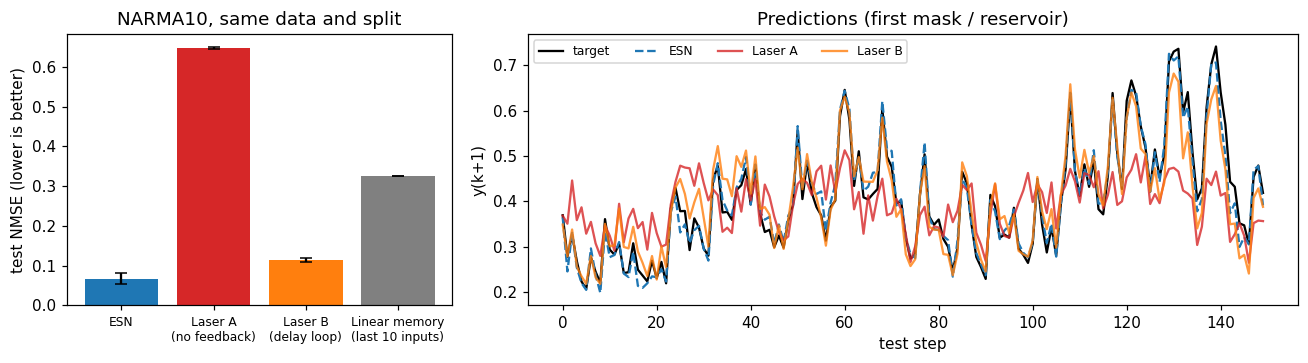

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1, 2]))

names = ["ESN", "Laser A\n(no feedback)", "Laser B\n(delay loop)", "Linear memory\n(last 10 inputs)"]
means = [esn_nmse, np.mean(laser_results["A (no feedback)"]), np.mean(laser_results["B (delay loop)"]), linear_memory_nmse]
stds = [esn_std,
        np.std(laser_results["A (no feedback)"]), np.std(laser_results["B (delay loop)"]), 0]
ax[0].bar(names, means, yerr=stds, color=["C0", "C3", "C1", "gray"], capsize=4)
ax[0].set_ylabel("test NMSE (lower is better)"); ax[0].set_title("NARMA10, same data and split")
ax[0].tick_params(axis="x", labelsize=8)

ax[1].plot(d[test][:150], color="k", label="target")
ax[1].plot(esn_prediction[:150], color="C0", ls="--", label="ESN")
ax[1].plot(laser_predictions["A (no feedback)"][:150], color="C3", alpha=0.8, label="Laser A")
ax[1].plot(laser_predictions["B (delay loop)"][:150], color="C1", alpha=0.8, label="Laser B")
ax[1].set_xlabel("test step"); ax[1].set_ylabel("y(k+1)"); ax[1].legend(fontsize=8, ncol=4)
ax[1].set_title("Predictions (first mask / reservoir)")
plt.tight_layout(); plt.show()

### 3.3 Why the score is what it is: memory and nonlinearity

NARMA10 needs two things from the reservoir (see Section 0): memory of inputs up to 9 steps back, and products of inputs such as u(k−9)·u(k). Each one is tested separately.

**Memory test.** A readout is trained to output a past input u(k−j), instead of y(k+1). The score R² is 1 if u(k−j) can be recovered exactly from the current recordings. It is 0 if it cannot be recovered at all.

**Nonlinearity test.** The same, but the target is the product ũ(k)·ũ(k−j), where ũ = u − mean(u). Removing the mean is important. Without it, part of the product equals a sum of u(k) and u(k−j), and a model with memory alone would score well. With the mean removed, a model that only remembers inputs, and cannot multiply them, scores R² ≈ 0.

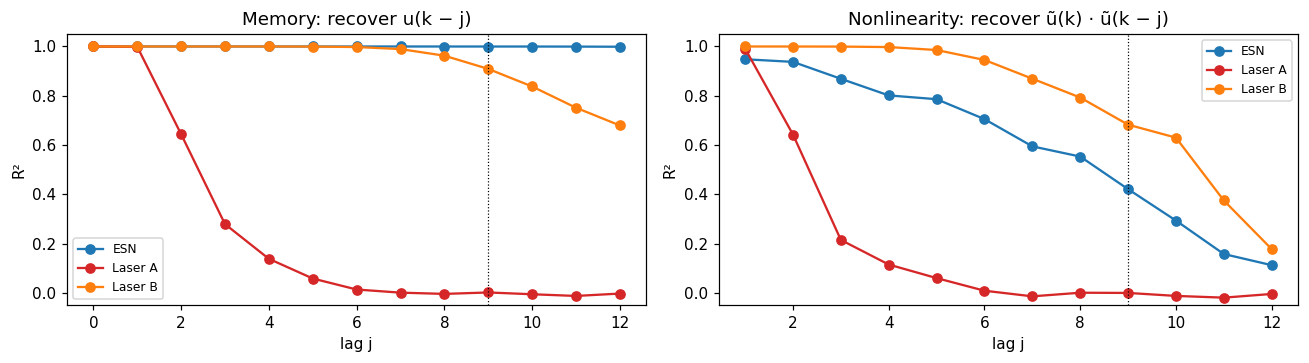

In [16]:
def recall_score(states_or_features, target, is_features=False):
    F = states_or_features if is_features else laser_features(states_or_features, u)
    W = train_readout(F[train], target[train], 1e-6)
    return 1 - nmse(F[val] @ W, target[val])

esn_F = features(run_esn(*make_esn(N_NODES, RHO, S_IN, 0), u), u)
lags = range(0, 13)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for label, F_or_states, is_F, color in [("ESN", esn_F, True, "C0"),
                                         ("Laser A", laser_states["A (no feedback)"], False, "C3"),
                                         ("Laser B", laser_states["B (delay loop)"], False, "C1")]:
    # Memory: recover u(k - lag). Drop the raw u(k) feature so only the reservoir is tested.
    F = F_or_states[:, :-2] if is_F else F_or_states
    ax[0].plot(lags, [recall_score(F, np.roll(u, lag), is_F) for lag in lags], "o-", color=color, label=label)
    # Nonlinearity: recover the product of mean-removed inputs
    u_c = u - u[train].mean()
    ax[1].plot(lags[1:], [recall_score(F, u_c * np.roll(u_c, lag), is_F) for lag in lags[1:]], "o-", color=color, label=label)
ax[0].set_xlabel("lag j"); ax[0].set_ylabel("R²"); ax[0].set_title("Memory: recover u(k − j)")
ax[1].set_xlabel("lag j"); ax[1].set_ylabel("R²"); ax[1].set_title("Nonlinearity: recover ũ(k) · ũ(k − j)")
for a in ax: a.axvline(9, color="k", ls=":", lw=0.8); a.set_ylim(-0.05, 1.05); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.4 What Section 3 shows

| Model | Test NMSE |
|---|---|
| ESN | 0.067 ± 0.014 |
| Laser B, delay loop | 0.115 ± 0.005 |
| Linear memory reference (last 10 inputs, no reservoir) | 0.326 |
| Laser A, no feedback | 0.648 ± 0.003 |

**Laser A (the particle alone) does not solve NARMA10.** Its memory lasts about 2 input steps (R² = 0.64 at lag 2, 0.28 at lag 3). This agrees with Section 2: the laser settles within a few τ. With the best settings, one input window is only N·θ = 0.5 τ. NARMA10 needs lag 9.

**Laser B (with the delay loop) works well.** It scores far below the linear memory reference, so its nonlinearity helps. It keeps inputs up to lag 9 (R² ≥ 0.9). It recovers products of inputs up to lag 9 better than the ESN does. It is still about 1.7× worse than the ESN. A possible reason: the NARMA10 output depends on its own past outputs, so inputs older than 10 steps matter a little. The ESN keeps those inputs (R² ≈ 1 at lag 12). Laser B keeps them less well (R² ≈ 0.7). This has not been tested directly.

**A small input strength is necessary.** With γ = 0.5 or more (the first grid), Laser B scored 0.46, and its memory ended after about 6 steps. With γ = 0.05 it scores 0.115. A strong input changes the laser state a lot at every step. This erases the information from earlier inputs.

**Open points.**
- γ = 0.05 is the smallest value tried, so it is at the edge of the grid. Smaller values are not tried on purpose. The model has no noise, so even very small pump changes are measured perfectly. A smaller γ would only make use of that. In a real laser, the noise would be larger than changes this small. **So the laser scores here are too optimistic.** Section 5 adds noise.
- Only one β is tested, with a limited grid of drive settings.

## 4. Exploration: how does the photon lifetime τ_c affect performance?

**Why τ_c.** Section 3 showed that the laser alone (A) does not remember inputs for long enough. τ_c sets how fast the laser responds. It is also a property of the particle design (size, shape, surface quality). So the result tells the lab which particles to make.

**Prediction before running.** Standard laser theory gives two numbers for the oscillations after a pump change (relaxation oscillations):
- their frequency is about √((p − 1)/(τ·τ_c)). This depends on τ_c.
- their decay rate is about p/(2τ). This does not depend on τ_c.

If this is right, τ_c changes how fast the laser oscillates, but not much how long it takes to settle. Then the score should change little.

**Method.** Five values, τ_c = 0.003 to 0.3 (in units of τ). β stays 1e-3. Pumps are given as p = P/P_th, so the threshold stays at p = 1. For each τ_c:
1. A step test (pump 1.05 → 1.15, near the operating point) measures the settling time.
2. The full Section 3 search and test, for both A and B.

The search takes about 8 minutes inside the notebook. (The smallest τ_c needs a smaller solver step.) The results are saved in `results/tau_c_sweep.json` and loaded here. Delete that file to compute them again.

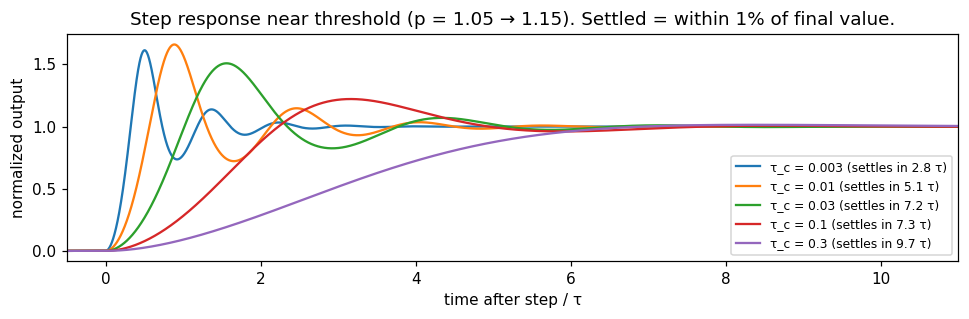

In [17]:
TAU_C_VALUES = [0.003, 0.01, 0.03, 0.1, 0.3]

# 4.1 Step test: settling time near the operating point
fig, ax = plt.subplots(figsize=(9, 3))
t_step = np.arange(-1, 12, 1e-4)
settle_times = {}
for tau_c in TAU_C_VALUES:
    p_step = np.where(t_step < 0, 1.05, 1.15)
    L_start, L_end = steady_output(1.05), steady_output(1.15)
    N_start = (1.05 / (1 + L_start)) * TAU / (BETA * tau_c)
    _, q = simulate_laser(p_step / (BETA * tau_c), dt=1e-4, tau_c=tau_c, N0=N_start, q0=L_start / BETA)
    response = (BETA * q - L_start) / (L_end - L_start)
    outside = np.where(np.abs(response - 1) > 0.01)[0]
    settle_times[tau_c] = t_step[outside[-1]]
    ax.plot(t_step, response, label=f"τ_c = {tau_c} (settles in {settle_times[tau_c]:.1f} τ)")
ax.set_xlabel("time after step / τ"); ax.set_ylabel("normalized output"); ax.set_xlim(-0.5, 11)
ax.set_title("Step response near threshold (p = 1.05 → 1.15). Settled = within 1% of final value.")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [18]:
import json, pathlib

# 4.2 Search and test for each tau_c (loaded from file if it exists)
sweep_file = pathlib.Path("results/tau_c_sweep.json")
if sweep_file.exists():
    sweep = json.loads(sweep_file.read_text())
else:
    sweep = {}
    for tau_c in TAU_C_VALUES:
        sweep[str(tau_c)] = {}
        for version, grid in GRIDS.items():
            r = tune_and_test(grid, tau_c)
            sweep[str(tau_c)][version[0]] = dict(val_nmse=r["val_nmse"], settings=r["settings"], test_nmse=r["test_nmse"])
        print(f"tau_c = {tau_c} done")
    sweep_file.parent.mkdir(exist_ok=True)
    sweep_file.write_text(json.dumps(sweep, indent=1))

print("tau_c    A: test NMSE       B: test NMSE       B settings")
for tau_c in TAU_C_VALUES:
    a, b = sweep[str(tau_c)]["A"], sweep[str(tau_c)]["B"]
    print(f"{tau_c:<7}  {np.mean(a['test_nmse']):.3f} ± {np.std(a['test_nmse']):.3f}    "
          f"{np.mean(b['test_nmse']):.3f} ± {np.std(b['test_nmse']):.3f}    {b['settings']}")

tau_c    A: test NMSE       B: test NMSE       B settings
0.003    0.649 ± 0.004    0.131 ± 0.005    {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}
0.01     0.648 ± 0.003    0.115 ± 0.005    {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}
0.03     0.646 ± 0.003    0.092 ± 0.006    {'p_bias': 1.3, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}
0.1      0.628 ± 0.005    0.081 ± 0.006    {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.5, 'eta': 0.6}
0.3      0.437 ± 0.001    0.109 ± 0.007    {'p_bias': 1.6, 'gamma': 0.05, 'theta': 0.5, 'eta': 0.9}


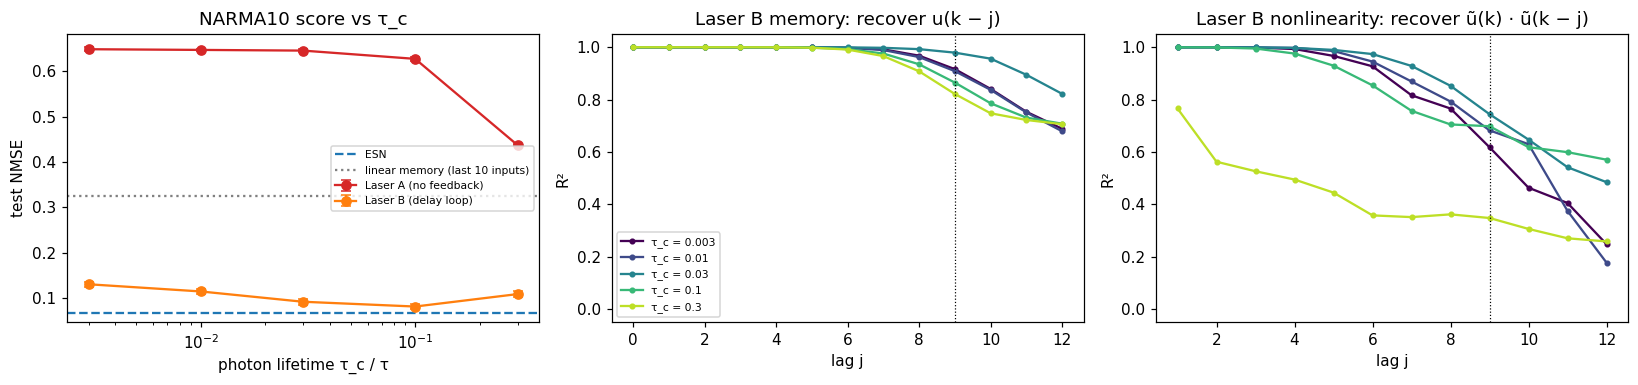

In [19]:
# 4.3 Memory and nonlinearity of version B for each tau_c (best settings, mask 0)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for version, color in [("A", "C3"), ("B", "C1")]:
    means = [np.mean(sweep[str(t)][version]["test_nmse"]) for t in TAU_C_VALUES]
    stds = [np.std(sweep[str(t)][version]["test_nmse"]) for t in TAU_C_VALUES]
    ax[0].errorbar(TAU_C_VALUES, means, yerr=stds, marker="o", color=color, capsize=3,
                   label="Laser A (no feedback)" if version == "A" else "Laser B (delay loop)")
ax[0].axhline(esn_nmse, color="C0", ls="--", label="ESN")
ax[0].axhline(linear_memory_nmse, color="gray", ls=":", label="linear memory (last 10 inputs)")
ax[0].set_xscale("log"); ax[0].set_xlabel("photon lifetime τ_c / τ"); ax[0].set_ylabel("test NMSE")
ax[0].set_title("NARMA10 score vs τ_c"); ax[0].legend(fontsize=7)

u_c = u - u[train].mean()
colors = plt.cm.viridis(np.linspace(0, 0.9, len(TAU_C_VALUES)))
for tau_c, color in zip(TAU_C_VALUES, colors):
    s = sweep[str(tau_c)]["B"]["settings"]
    states = run_laser_reservoir(u, make_mask(0), s["p_bias"], s["gamma"], s["theta"], s["eta"],
                                 solver_step(tau_c), BETA, tau_c)
    ax[1].plot(lags, [recall_score(states, np.roll(u, lag)) for lag in lags], "o-", ms=3, color=color, label=f"τ_c = {tau_c}")
    ax[2].plot(lags[1:], [recall_score(states, u_c * np.roll(u_c, lag)) for lag in lags[1:]], "o-", ms=3, color=color)
ax[1].set_title("Laser B memory: recover u(k − j)"); ax[2].set_title("Laser B nonlinearity: recover ũ(k) · ũ(k − j)")
for a in ax[1:]:
    a.set_xlabel("lag j"); a.set_ylabel("R²"); a.set_ylim(-0.05, 1.05); a.axvline(9, color="k", ls=":", lw=0.8)
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4.4 What Section 4 shows

**Settling time (step test).** Near threshold, the settling time grows from 2.8 τ (τ_c = 0.003) to 9.7 τ (τ_c = 0.3). The oscillations after a step become much slower. At τ_c = 0.3 there are no oscillations: the output rises smoothly.

**Score.**
- **Laser A** is poor at every τ_c: about 0.65, and 0.44 only at τ_c = 0.3. It is always worse than the linear memory reference. A slower particle alone is not enough.
- **Laser B** changes only a little: 0.131 at τ_c = 0.003, best 0.081 at τ_c = 0.1, then 0.109 at τ_c = 0.3. A 100-fold change in τ_c changes the score about 1.6-fold.
- **The best τ_c is in the middle of the range.** A small τ_c gives slightly shorter memory. At τ_c = 0.3 the laser recovers products of inputs much less well (R² ≈ 0.56 already at lag 2). Its best settings also move far above threshold (p_bias = 1.6), where the output curve is almost straight.

**The prediction was mostly correct.** τ_c has a small effect. For comparison, changing the input strength γ at τ_c = 0.01 changed the score from 0.46 to 0.115.

**What this means for the lab.** Real perovskite particles probably have τ_c far below 0.01 τ, at the low end of this range. There, Laser B still scores 0.131. This is below the linear memory reference (0.326). So the photon lifetime does not prevent the use of these particles as a reservoir. A delay loop and a small input strength matter more.

**Limits of this result.**
- No noise (see Section 3.4). The small γ that works best is the setting that noise would hurt most.
- At τ_c = 0.3, several best settings are at the edge of the grid (p_bias = 1.6, η = 0.9, θ = 0.5). So a wider grid might give a lower score at that point.
- τ_c changes two things at once: the oscillation speed and the settling time.

## 5. The laser's own noise

**Problem.** Sections 3 and 4 have no noise. The best setting uses a very small input (γ = 0.05). So the laser output changes only a little from one input to the next. The simulation measures these small changes perfectly. A real laser output also changes at random. These random changes could be larger than the effect of the input.

**Noise model.** Carriers and photons are created and lost one at a time, at random moments. These processes are: the pump, stimulated emission, spontaneous emission into the laser mode, other spontaneous emission, and photons leaving the particle. In each short step dt, each process happens a random number of times, with variance = rate × dt (Poisson statistics). This adds no new free parameter. The size of the noise depends on the photon number, which is set by β, τ_c and the pump. With β = 1e-3 the laser holds a few hundred photons.

**Solver.** Equations with random terms need a different method: Euler–Maruyama, with step 0.0025 τ (τ_c/4). Without noise it gives the same score as the Section 3 solver (0.106 vs 0.107 for one mask). It uses the raw numbers N₁ and q instead of the normalized ones.

In [20]:
@njit(cache=True)
def run_noisy_laser(u, mask, p_bias, gamma, theta, eta, dt, beta, tau_c, noise, seed, average=False):
    """Same reservoir as run_laser_reservoir, in raw numbers (N1 carriers, q photons, TAU = 1), with noise.

    Each process has Poisson statistics: in a step dt its count has variance rate * dt.
    average=True records the mean output over each slot (a detector integrating the light)
    instead of the value at the end of the slot.
    """
    np.random.seed(seed)
    n_nodes = mask.size
    steps_per_slot = int(round(theta / dt))
    delay_steps = n_nodes * steps_per_slot
    p_th = 1.0 / (beta * tau_c)
    history = np.zeros(delay_steps)
    states = np.empty((u.size, n_nodes))
    N, q = 0.0, 0.0
    j = 0
    sqdt = np.sqrt(dt)
    for k in range(u.size):
        for i in range(n_nodes):
            total = 0.0
            for _ in range(steps_per_slot):
                p = p_bias + gamma * mask[i] * u[k] + eta * history[j]
                P = max(p, 0.0) * p_th
                into_mode = beta * N * q + beta * N      # stimulated + spontaneous into the mode
                other = (1.0 - beta) * N                 # spontaneous emission into other modes
                loss = q / tau_c
                dN = (P - into_mode - other) * dt
                dq = (into_mode - loss) * dt
                if noise:
                    x = np.sqrt(into_mode) * sqdt * np.random.randn()   # one carrier becomes one photon
                    dN += -x + np.sqrt(P + other) * sqdt * np.random.randn()
                    dq += x - np.sqrt(loss) * sqdt * np.random.randn()
                N = max(N + dN, 0.0)
                q = max(q + dq, 0.0)
                history[j] = beta * q
                j = (j + 1) % delay_steps
                total += beta * q
            states[k, i] = total / steps_per_slot if average else beta * q
    return states


DT_NOISE = 0.0025


def noisy_test_score(settings, beta=BETA, noise=True, average=False, seed=0):
    s = settings
    states = run_noisy_laser(u, make_mask(seed), s["p_bias"], s["gamma"], s["theta"], s["eta"],
                             DT_NOISE, beta, TAU_C, noise, seed, average)
    F = laser_features(states, u)
    W_out = train_readout(F[train_val], d[train_val], best_ridge(F))
    return nmse(F[test] @ W_out, d[test]), states

### 5.1 The Section 3 best setting, with and without noise

Same settings (Laser B, γ = 0.05) and same mask. The plot shows the 100 recordings for one input step.

Laser B, Section 3 settings {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}
  without noise: test NMSE 0.106
  with noise:    test NMSE 0.769
  mean photon number in the laser: 150


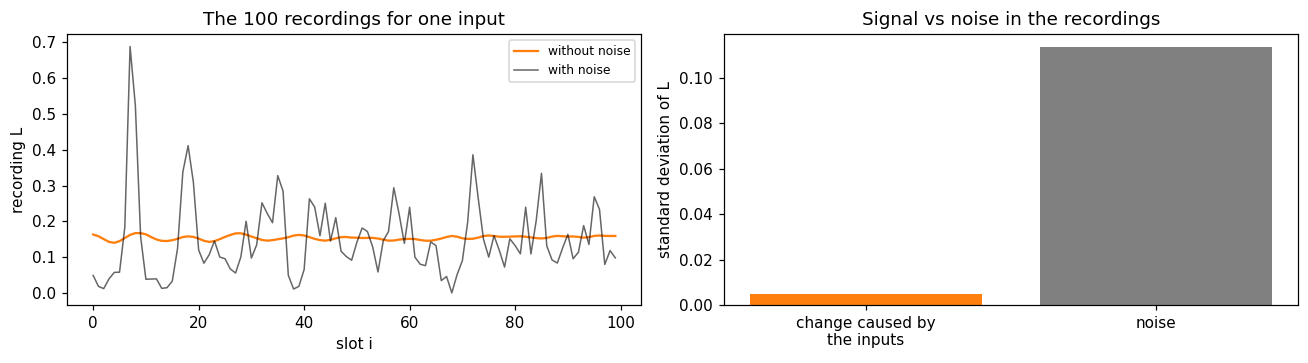

In [21]:
best_B = laser["B (delay loop)"]["settings"]
score_clean, states_clean = noisy_test_score(best_B, noise=False)
score_noisy, states_noisy = noisy_test_score(best_B, noise=True)
print(f"Laser B, Section 3 settings {best_B}")
print(f"  without noise: test NMSE {score_clean:.3f}")
print(f"  with noise:    test NMSE {score_noisy:.3f}")
print(f"  mean photon number in the laser: {states_noisy[train].mean() / BETA:.0f}")

k_show = test.start + 10
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(states_clean[k_show], color="C1", label="without noise")
ax[0].plot(states_noisy[k_show], color="k", alpha=0.6, lw=1, label="with noise")
ax[0].set_xlabel("slot i"); ax[0].set_ylabel("recording L"); ax[0].set_title("The 100 recordings for one input")
ax[0].legend(fontsize=8)
# How much each recording changes from one input to the next, compared with the noise
change = np.std(np.diff(states_clean[test], axis=0))
jitter = np.std(states_noisy[test] - states_clean[test])
ax[1].bar(["change caused by\nthe inputs", "noise"], [change, jitter], color=["C1", "gray"])
ax[1].set_ylabel("standard deviation of L"); ax[1].set_title("Signal vs noise in the recordings")
plt.tight_layout(); plt.show()

### 5.2 Settings chosen again with noise, for four values of β

With noise, a different setting may be best. For example, a larger input changes the output more, compared with the noise. So the drive settings are searched again with noise on, using the same validation method as Section 3.

β is also changed. A smaller β means more photons in the laser, so the noise is smaller compared with the output. (β also changes the shape of the threshold, so this changes two things at once.)

The search tries 792 settings and takes about 5 minutes with 8 processes. So it is in a separate script, `scripts/noise_search.py`. The script uses the same data, split, masks, solver and readout as this notebook. Its results are saved in `results/noise_search.json` and loaded here.

beta      photons   A with noise     B with noise     B same settings, no noise   B settings
0.01           45   0.773 ± 0.018    0.710 ± 0.015    0.266                       {'p_bias': 1.1, 'gamma': 1.0, 'theta': 0.2, 'eta': 0.6}
0.001         458   0.727 ± 0.015    0.672 ± 0.014    0.581                       {'p_bias': 1.1, 'gamma': 1.0, 'theta': 0.5, 'eta': 0.6}
0.0001       4613   0.721 ± 0.018    0.671 ± 0.020    0.637                       {'p_bias': 1.1, 'gamma': 1.0, 'theta': 0.5, 'eta': 0.6}
1e-05       14971   0.695 ± 0.012    0.611 ± 0.011    0.513                       {'p_bias': 1.1, 'gamma': 0.2, 'theta': 0.5, 'eta': 0.3}


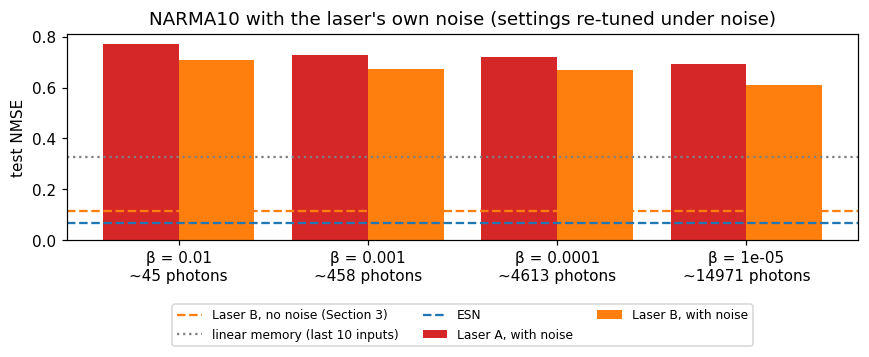

In [22]:
noise_file = pathlib.Path("results/noise_search.json")
if not noise_file.exists():
    print("results/noise_search.json not found. Run `python3 scripts/noise_search.py` from the project folder, "
          "or upload the file to results/ (in Colab: the Files panel).")
else:
    noise_results = json.loads(noise_file.read_text())
    BETAS = sorted(noise_results, key=float, reverse=True)
    print("beta      photons   A with noise     B with noise     B same settings, no noise   B settings")
    for b in BETAS:
        A, B = noise_results[b]["A"], noise_results[b]["B"]
        print(f"{float(b):<8g}  {B['mean_photons']:>7.0f}   {np.mean(A['test_nmse']):.3f} ± {np.std(A['test_nmse']):.3f}    "
              f"{np.mean(B['test_nmse']):.3f} ± {np.std(B['test_nmse']):.3f}    {np.mean(B['test_nmse_without_noise']):.3f}"
              f"                       {B['settings']}")

    fig, ax = plt.subplots(figsize=(8, 3.6))
    x = np.arange(len(BETAS))
    ax.bar(x - 0.2, [np.mean(noise_results[b]["A"]["test_nmse"]) for b in BETAS], 0.4, color="C3", label="Laser A, with noise")
    ax.bar(x + 0.2, [np.mean(noise_results[b]["B"]["test_nmse"]) for b in BETAS], 0.4, color="C1", label="Laser B, with noise")
    ax.axhline(np.mean(laser_results["B (delay loop)"]), color="C1", ls="--", label="Laser B, no noise (Section 3)")
    ax.axhline(linear_memory_nmse, color="gray", ls=":", label="linear memory (last 10 inputs)")
    ax.axhline(esn_nmse, color="C0", ls="--", label="ESN")
    ax.set_xticks(x, [f"β = {float(b):g}\n~{noise_results[b]['B']['mean_photons']:.0f} photons" for b in BETAS])
    ax.set_ylabel("test NMSE"); ax.set_title("NARMA10 with the laser's own noise (settings re-tuned under noise)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3); plt.tight_layout(); plt.show()

### 5.3 Check: recording the average light over each slot

So far, each recording is the output at one moment. A real detector collects light over the whole slot. This averages out part of the noise. Both methods are compared here, with noise, for two settings: the Section 3 setting, and the setting chosen with noise (β = 1e-3). Runtime: about 10 s.

In [23]:
if noise_file.exists():
    for label, s in [("Section 3 setting", best_B), ("re-tuned under noise", noise_results["0.001"]["B"]["settings"])]:
        instant, _ = noisy_test_score(s, noise=True, average=False)
        averaged, _ = noisy_test_score(s, noise=True, average=True)
        print(f"{label:<22} {s}:  instant {instant:.3f}   averaged over slot {averaged:.3f}")

Section 3 setting      {'p_bias': 1.1, 'gamma': 0.05, 'theta': 0.2, 'eta': 0.3}:  instant 0.769   averaged over slot 0.781


re-tuned under noise   {'p_bias': 1.1, 'gamma': 1.0, 'theta': 0.5, 'eta': 0.6}:  instant 0.649   averaged over slot 0.544


### 5.4 What Section 5 shows

**The noise is much larger than the signal.** At the Section 3 setting, the noise in each recording (standard deviation 0.11) is about 20 times larger than the change the inputs cause (0.005). Near threshold, the photon number varies much more than √(photon number). In the plot it rises to more than 4 times its average. The laser is noisiest where it is most nonlinear.

**With noise, the delay loop no longer gives a useful result.**
- At the Section 3 setting, Laser B goes from test NMSE 0.106 (no noise) to 0.769 (with noise).
- With settings chosen again under noise, Laser B scores 0.67 at β = 1e-3. Its best score is 0.61, with about 15,000 photons (β = 1e-5).
- Every result with noise is worse than the linear memory reference (0.33), which uses no reservoir. Laser A scores 0.70–0.77.
- With noise, the search picks a 20× larger input (γ = 1.0), so that the effect of the input is larger than the noise. But a large input erases older information (Section 3.4). So memory is lost in both cases.

**Averaging over each slot helps a little.** For the setting chosen with noise, the score goes from 0.649 to 0.544. The conclusion stays the same.

**What this means.** The result without noise depended on measuring changes much smaller than the laser's own quantum noise. A realistic laser-particle reservoir would need one or more of these:
- many more photons: larger particles, or a pump far above threshold. (Far above threshold, the output is less nonlinear.)
- repeated measurements, or many particles at once, averaged together.
- tasks that need less memory than NARMA10.

**Limits of this result.**
- Some best settings are at the edge of the grid (γ = 1.0 is the largest value tried; p_bias = 1.1 is the smallest).
- The pump is assumed to have Poisson noise too. A pump laser with less noise would help a little.
- Changing β also changes the shape of the threshold, so the β comparison changes two things at once.
- The solver step for the noise model was checked only without noise, against the Section 3 solver.